<a href="https://colab.research.google.com/github/Murcha1990/GenModels_AI26/blob/main/Seminars_Base/Sem5_StDiffusion_AR/GenDL_Autoregressive_Image_Modeling.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Авторегрессионная генерация изображений: PixelCNN

## 0. Идея

Вспомним GPT: модель читает текст слева направо и на каждом шаге предсказывает **следующий токен** по всем предыдущим.

PixelCNN делает то же самое с картинкой: вытягиваем пиксели в одну строку (слева направо, сверху вниз) и предсказываем **следующий пиксель** по всем предыдущим (синие на рисунке):

<center width="100%" style="padding: 10px"><img src="https://github.com/phlippe/uvadlc_notebooks/blob/master/docs/tutorial_notebooks/tutorial12/autoregressive_image_modeling.svg?raw=1" width="200px"></center>

Формально, вероятность всей картинки раскладывается в произведение (это просто цепное правило для вероятностей):

$$
p(\mathbf{x}) = \prod_{i=1}^{n} p(x_i \mid x_1, \dots, x_{i-1})
$$

**Как предсказать один пиксель?** Пиксель в MNIST — целое число от 0 до 255. Значит, это обычная **классификация на 256 классов**: на выходе softmax, функция потерь — cross-entropy. Как «словарь из 256 токенов» у языковой модели.

**Плюсы:** простое и честное обучение (просто cross-entropy), можно точно посчитать вероятность любой картинки.

**Минусы:** генерация медленная — для картинки 28×28 нужно 784 прохода сети, по одному на пиксель.

Дальше вопрос один: **как сделать свёрточную сеть, которая для каждого пикселя смотрит только на «прошлые» пиксели?**

### Подготовка (просто запускаем)

In [1]:
import os, math
import numpy as np
import matplotlib.pyplot as plt
plt.set_cmap('cividis')
%matplotlib inline
from tqdm.notebook import tqdm

import torch
import torch.nn as nn
import torch.nn.functional as F
import torch.utils.data as data
import torch.optim as optim
import torchvision
from torchvision.datasets import MNIST
from torchvision import transforms

try:
    import pytorch_lightning as pl
except ModuleNotFoundError:  # в Colab Lightning по умолчанию не установлен
    !pip install --quiet pytorch-lightning>=1.4
    import pytorch_lightning as pl
from pytorch_lightning.callbacks import LearningRateMonitor, ModelCheckpoint

DATASET_PATH = "../data"                      # куда скачать MNIST
CHECKPOINT_PATH = "../saved_models/ar_models" # куда скачать обученную модель

pl.seed_everything(42)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

device = torch.device("cuda:0") if torch.cuda.is_available() else torch.device("cpu")
print("Using device", device)

INFO:lightning_fabric.utilities.seed:Seed set to 42


Using device cuda:0


<Figure size 640x480 with 0 Axes>

In [2]:
import urllib.request
from urllib.error import HTTPError
# Github URL where saved models are stored for this tutorial
base_url = "https://raw.githubusercontent.com/phlippe/saved_models/main/tutorial12/"
# Files to download
pretrained_files = ["PixelCNN.ckpt"]
# Create checkpoint path if it doesn't exist yet
os.makedirs(CHECKPOINT_PATH, exist_ok=True)

# For each file, check whether it already exists. If not, try downloading it.
for file_name in pretrained_files:
    file_path = os.path.join(CHECKPOINT_PATH, file_name)
    if not os.path.isfile(file_path):
        file_url = base_url + file_name
        print(f"Downloading {file_url}...")
        try:
            urllib.request.urlretrieve(file_url, file_path)
        except HTTPError as e:
            print("Something went wrong. Please try to download the file from the GDrive folder, or contact the author with the full output including the following error:\n", e)

Данные — MNIST. Значения пикселей переводим в **целые числа 0…255**: это одновременно и вход модели, и «правильные классы» для предсказания.

In [3]:
# Convert images from 0-1 to 0-255 (integers). We use the long datatype as we will use the images as labels as well
def discretize(sample):
    return (sample * 255).to(torch.long)

# Transformations applied on each image => only make them a tensor
transform = transforms.Compose([transforms.ToTensor(),
                                discretize])

# Loading the training dataset. We need to split it into a training and validation part
train_dataset = MNIST(root=DATASET_PATH, train=True, transform=transform, download=True)
pl.seed_everything(42)
train_set, val_set = torch.utils.data.random_split(train_dataset, [50000, 10000])

# Loading the test set
test_set = MNIST(root=DATASET_PATH, train=False, transform=transform, download=True)

# We define a set of data loaders that we can use for various purposes later.
train_loader = data.DataLoader(train_set, batch_size=128, shuffle=True, drop_last=True, pin_memory=True, num_workers=4)
val_loader = data.DataLoader(val_set, batch_size=128, shuffle=False, drop_last=False, num_workers=4)
test_loader = data.DataLoader(test_set, batch_size=128, shuffle=False, drop_last=False, num_workers=4)

100%|██████████| 9.91M/9.91M [00:00<00:00, 18.3MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 501kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.84MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.02MB/s]
INFO:lightning_fabric.utilities.seed:Seed set to 42
/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 4 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()


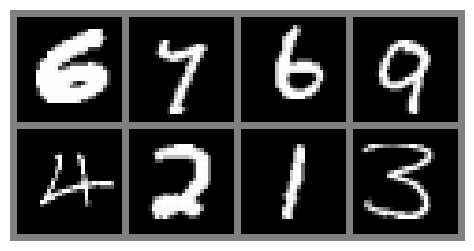

In [4]:
def show_imgs(imgs):
    num_imgs = imgs.shape[0] if isinstance(imgs, torch.Tensor) else len(imgs)
    nrow = min(num_imgs, 4)
    ncol = int(math.ceil(num_imgs/nrow))
    imgs = torchvision.utils.make_grid(imgs, nrow=nrow, pad_value=128)
    imgs = imgs.clamp(min=0, max=255)
    np_imgs = imgs.cpu().numpy()
    plt.figure(figsize=(1.5*nrow, 1.5*ncol))
    plt.imshow(np.transpose(np_imgs, (1,2,0)), interpolation='nearest')
    plt.axis('off')
    plt.show()
    plt.close()

show_imgs([train_set[i][0] for i in range(8)])

## 1. Маскированная свёртка

Обычная свёртка 3×3 или 5×5 смотрит на соседей **со всех сторон**, в том числе на сам пиксель и на пиксели правее и ниже. Для нас это «подглядывание в будущее»: при генерации этих пикселей ещё нет.

Решение простое: **обнуляем часть весов ядра**, чтобы фильтр видел только пиксели выше и левее. Пример маски для ядра 5×5 (единицы — разрешённые веса):

<center width="100%" style="padding: 10px"><img src="https://github.com/phlippe/uvadlc_notebooks/blob/master/docs/tutorial_notebooks/tutorial12/masked_convolution.svg?raw=1" width="150px"></center>

В коде это обычный `nn.Conv2d`, у которого перед каждым применением веса умножаются на маску из 0 и 1:

In [5]:
class MaskedConvolution(nn.Module):

    def __init__(self, c_in, c_out, mask, **kwargs):
        """
        Implements a convolution with mask applied on its weights.
        Inputs:
            c_in - Number of input channels
            c_out - Number of output channels
            mask - Tensor of shape [kernel_size_H, kernel_size_W] with 0s where
                   the convolution should be masked, and 1s otherwise.
            kwargs - Additional arguments for the convolution
        """
        super().__init__()
        # For simplicity: calculate padding automatically
        kernel_size = (mask.shape[0], mask.shape[1])
        dilation = 1 if "dilation" not in kwargs else kwargs["dilation"]
        padding = tuple([dilation*(kernel_size[i]-1)//2 for i in range(2)])
        # Actual convolution
        self.conv = nn.Conv2d(c_in, c_out, kernel_size, padding=padding, **kwargs)

        # Mask as buffer => it is no parameter but still a tensor of the module
        # (must be moved with the devices)
        self.register_buffer('mask', mask[None,None])

    def forward(self, x):
        self.conv.weight.data *= self.mask # Ensures zero's at masked positions
        return self.conv(x)

## 2. Слепое пятно и два потока свёрток

Логичная первая идея: просто поставить друг на друга несколько маскированных свёрток. Так и было сделано в первой версии PixelCNN. Но оказывается, что у такой сети есть **слепое пятно**: пиксели **выше и правее** текущего никогда не влияют на предсказание, хотя они уже известны.

Почему так: информация от пикселя P (выше и правее X) должна дойти до X через соседей на предыдущих слоях. Но каждый сосед на своём слое тоже «не смотрит вправо», и путь обрывается.

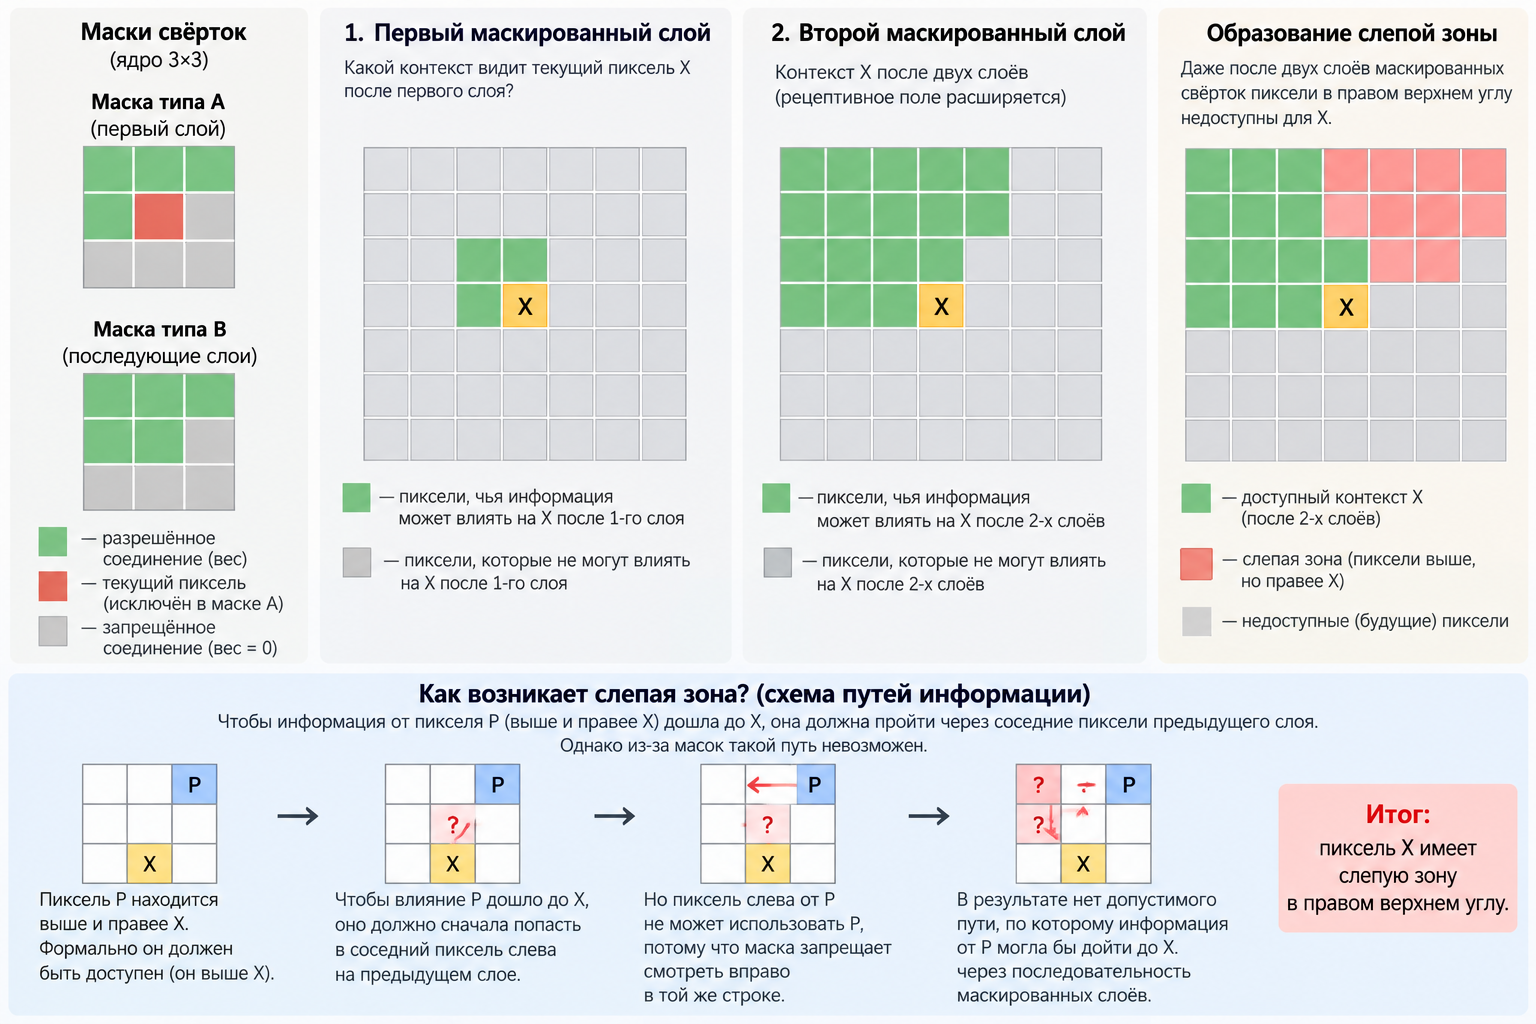

**Проверим это кодом.** Чтобы увидеть, какие пиксели входа влияют на выход в центре, считаем градиент центрального выхода по входной картинке: где градиент не ноль, те пиксели и входят в **поле восприятия** (receptive field).

In [6]:
inp_img = torch.zeros(1, 1, 11, 11)
inp_img.requires_grad_()

def show_center_recep_field(img, out):
    '''Показывает, какие пиксели входа img влияют на центральный пиксель выхода out.'''
    # «Фиктивный лосс» = значение центрального выходного пикселя; считаем его градиент по входу
    loss = out[0, :, img.shape[2]//2, img.shape[3]//2].sum()
    loss.backward(retain_graph=True)
    img_grads = img.grad.abs()
    img.grad.fill_(0)

    img = img_grads.squeeze().cpu().numpy()
    fig, ax = plt.subplots(1, 2)
    ax[0].imshow(img)
    ax[1].imshow(img > 0)
    # Центральный пиксель отмечаем красным, если он сам на себя не влияет
    show_center = (img[img.shape[0]//2, img.shape[1]//2] == 0)
    if show_center:
        center_pixel = np.zeros(img.shape + (4,))
        center_pixel[center_pixel.shape[0]//2, center_pixel.shape[1]//2, :] = np.array([1.0, 0.0, 0.0, 1.0])
    for i in range(2):
        ax[i].axis('off')
        if show_center:
            ax[i].imshow(center_pixel)
    ax[0].set_title("Weighted receptive field")
    ax[1].set_title("Binary receptive field")
    plt.show()
    plt.close()

Соберём «наивную» сеть: 4 одинаковых маскированных свёртки 3×3 подряд (маска как на схеме: вся строка выше + пиксель слева). Все веса = 1, чтобы было видно только *какие* пиксели влияют.

**Как читать картинки ниже:** жёлтое — пиксели, которые влияют на предсказание, тёмное — не влияют, красный — сам предсказываемый пиксель. Слева сила влияния (weighted), справа просто «да/нет» (binary).

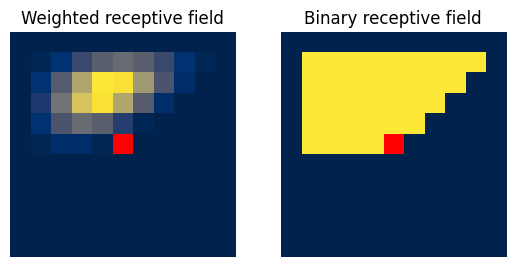

In [7]:
def naive_mask(k=3, mask_center=False):
    mask = torch.ones(k, k)
    mask[k//2+1:, :] = 0      # строки ниже — нельзя
    mask[k//2, k//2+1:] = 0   # правее в той же строке — нельзя
    if mask_center:
        mask[k//2, k//2] = 0  # на первом слое нельзя видеть и сам пиксель
    return mask

inp_naive = torch.zeros(1, 1, 11, 11, requires_grad=True)
x = inp_naive
for layer_idx in range(4):
    conv = MaskedConvolution(1, 1, naive_mask(3, mask_center=(layer_idx == 0)))
    conv.conv.weight.data.fill_(1)
    conv.conv.bias.data.fill_(0)
    x = conv(x)

show_center_recep_field(inp_naive, x)

Вот оно: треугольник **справа сверху** остаётся тёмным, хотя эти пиксели уже известны. Это и есть слепое пятно, и с глубиной оно не исчезает.

### Решение: два потока признаков

Разделим сеть на два «потока» (stack):

* **Вертикальный поток** отвечает за всё, что **выше** текущей строки. Ему можно смотреть на строку выше **целиком**, в том числе правее: всё это уже прошлое. Поэтому слепого пятна у него нет.
* **Горизонтальный поток** отвечает за пиксели **левее в текущей строке**. Кроме того, он **получает признаки вертикального потока**. Именно его выход используется для предсказания пикселя.

Главное правило: **информация течёт только из вертикального в горизонтальный, но не обратно.** Вертикальная свёртка смотрит и вправо, а горизонтальные признаки уже знают пиксели текущей строки. Если подмешать их в вертикальный поток, то через «правого соседа» модель увидит текущий пиксель, то есть подсмотрит ответ.

Можно представить двух помощников: один изучает всё, что выше, и пересказывает это второму; второй идёт по текущей строке слева направо и делает предсказание. Второй слушает первого, а первый второго нет.

Реализация: вертикальная маска k×k (строки ниже центра обнулены), горизонтальная маска 1×k (правее центра обнулено):

In [8]:
class VerticalStackConvolution(MaskedConvolution):

    def __init__(self, c_in, c_out, kernel_size=3, mask_center=False, **kwargs):
       # Создаётся квадратная матрица из единиц (kernel_size × kernel_size), которая будет маской.
       # Все элементы ниже центральной строки зануляются (=0) → это значит, что фильтр не может смотреть вниз
       # (т.е. на пиксели ниже текущего).
        mask = torch.ones(kernel_size, kernel_size)
        mask[kernel_size//2+1:,:] = 0

       # Если mask_center=True, то обнуляется центральная строка, то есть пиксель не видит даже себя самого.
       # Это используется при самой первой свёртке, чтобы не допустить “подглядывания” текущего значения.
        if mask_center:
            mask[kernel_size//2,:] = 0

        super().__init__(c_in, c_out, mask, **kwargs)

class HorizontalStackConvolution(MaskedConvolution):

    def __init__(self, c_in, c_out, kernel_size=3, mask_center=False, **kwargs):
        mask = torch.ones(1,kernel_size)
        mask[0,kernel_size//2+1:] = 0

        if mask_center:
            mask[0,kernel_size//2] = 0

        super().__init__(c_in, c_out, mask, **kwargs)

`mask_center=True` нужен только **на самом первом слое**: на входе лежит сама картинка, и пиксель не должен видеть своё значение. На следующих слоях в позиции пикселя лежат уже признаки, посчитанные только по прошлому, поэтому центр можно не маскировать.

Посмотрим на поля восприятия. **Одна горизонтальная свёртка** видит только пиксель слева:

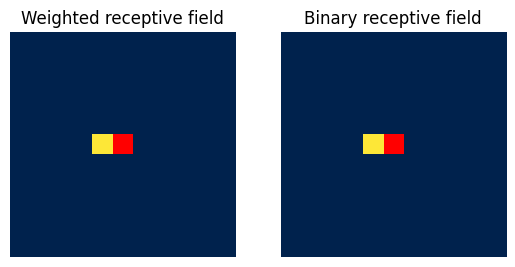

In [9]:
horiz_conv = HorizontalStackConvolution(c_in=1, c_out=1, kernel_size=3, mask_center=True)
horiz_conv.conv.weight.data.fill_(1)
horiz_conv.conv.bias.data.fill_(0)
horiz_img = horiz_conv(inp_img)
show_center_recep_field(inp_img, horiz_img)

**Одна вертикальная свёртка** видит строку выше:

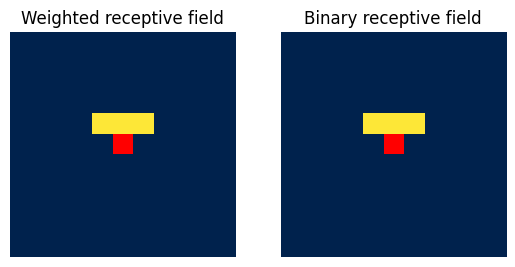

In [10]:
vert_conv = VerticalStackConvolution(c_in=1, c_out=1, kernel_size=3, mask_center=True)
vert_conv.conv.weight.data.fill_(1)
vert_conv.conv.bias.data.fill_(0)
vert_img = vert_conv(inp_img)
show_center_recep_field(inp_img, vert_img)

**Сумма двух потоков** даёт то же, что одна маскированная свёртка:

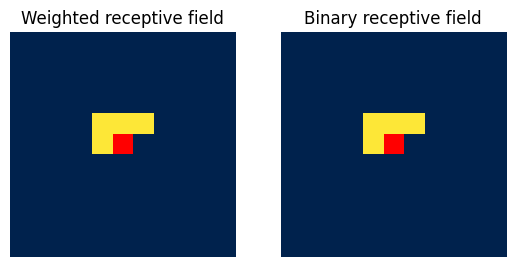

In [11]:
horiz_img = vert_img + horiz_img
show_center_recep_field(inp_img, horiz_img)

Теперь сложим **4 слоя** по правилу выше: вертикальный поток берёт только свои признаки, горизонтальный — свои плюс вертикальные.

Layer 2


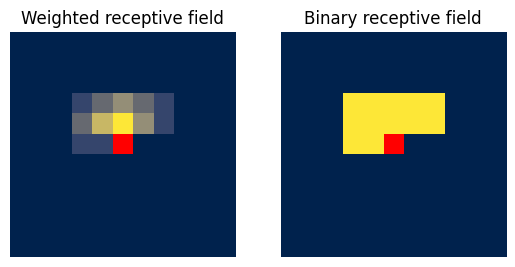

Layer 3


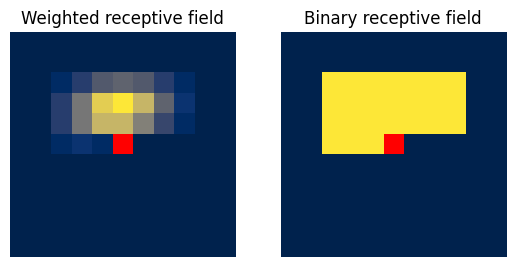

Layer 4


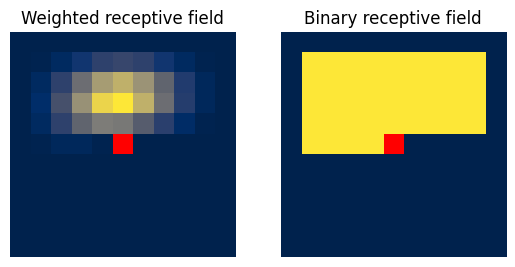

Layer 5


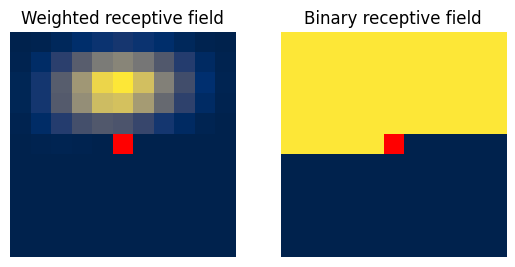

In [12]:
# Initialize convolutions with equal weight to all input pixels
horiz_conv = HorizontalStackConvolution(c_in=1, c_out=1, kernel_size=3, mask_center=False)
horiz_conv.conv.weight.data.fill_(1)
horiz_conv.conv.bias.data.fill_(0)
vert_conv = VerticalStackConvolution(c_in=1, c_out=1, kernel_size=3,mask_center=False)
vert_conv.conv.weight.data.fill_(1)
vert_conv.conv.bias.data.fill_(0)

# We reuse our convolutions for the 4 layers here. Note that in a standard network,
# we don't do that, and instead learn 4 separate convolution. As this cell is only for
# visualization purposes, we reuse the convolutions for all layers.
for l_idx in range(4):
    vert_img = vert_conv(vert_img)
    horiz_img = horiz_conv(horiz_img) + vert_img
    print(f"Layer {l_idx+2}")
    show_center_recep_field(inp_img, horiz_img)

Поле восприятия растёт с каждым слоем, и **слепого пятна больше нет**: видны все пиксели выше (в том числе правее) и левее в текущей строке.

А у вертикального потока, как и задумано, только пиксели выше:

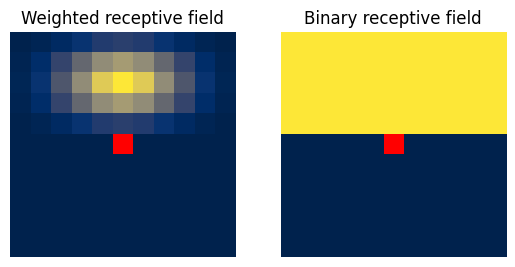

In [13]:
show_center_recep_field(inp_img, vert_img)

In [ ]:
del inp_img, horiz_conv, vert_conv

## 3. Модель целиком (кратко)

Настоящий **Gated PixelCNN** устроен так:

1. Первые вертикальная и горизонтальная свёртки с `mask_center=True`.
2. Несколько **gated-блоков**. Это те же два потока, только вместо ReLU используется «гейт», как в LSTM:
   $\;\text{выход} = \tanh(\text{сигнал}) \cdot \sigma(\text{гейт})$. Сигмоида решает, какую долю информации пропустить.
   В некоторых блоках есть **dilation** (свёртка «через пиксель»): так модель видит больше контекста без увеличения числа весов.
3. В конце свёртка 1×1, которая для каждого пикселя выдаёт **256 логитов**, по одному на каждое возможное значение.

Схема одного gated-блока (слева вертикальный поток, справа горизонтальный; видно, что стрелка идёт только слева направо):

<center width="100%"><img src="https://github.com/phlippe/uvadlc_notebooks/blob/master/docs/tutorial_notebooks/tutorial12/PixelCNN_GatedConv.svg?raw=1" width="600px" style="padding: 15px"/></center>

Код ниже можно не разбирать построчно. Обратите внимание на две функции:
* `calc_likelihood` считает **BPD** (разберём в разделе 4);
* `sample` генерирует картинку **пиксель за пикселем** в тройном цикле.

In [14]:
class GatedMaskedConv(nn.Module):

    def __init__(self, c_in, **kwargs):
        """
        Gated Convolution block implemented the computation graph shown above.
        """
        super().__init__()
        self.conv_vert = VerticalStackConvolution(c_in, c_out=2*c_in, **kwargs)
        self.conv_horiz = HorizontalStackConvolution(c_in, c_out=2*c_in, **kwargs)
        self.conv_vert_to_horiz = nn.Conv2d(2*c_in, 2*c_in, kernel_size=1, padding=0)
        self.conv_horiz_1x1 = nn.Conv2d(c_in, c_in, kernel_size=1, padding=0)

    def forward(self, v_stack, h_stack):
        # Vertical stack (left)
        v_stack_feat = self.conv_vert(v_stack)
        v_val, v_gate = v_stack_feat.chunk(2, dim=1)
        v_stack_out = torch.tanh(v_val) * torch.sigmoid(v_gate)

        # Horizontal stack (right)
        h_stack_feat = self.conv_horiz(h_stack)
        h_stack_feat = h_stack_feat + self.conv_vert_to_horiz(v_stack_feat)
        h_val, h_gate = h_stack_feat.chunk(2, dim=1)
        h_stack_feat = torch.tanh(h_val) * torch.sigmoid(h_gate)
        h_stack_out = self.conv_horiz_1x1(h_stack_feat)
        h_stack_out = h_stack_out + h_stack

        return v_stack_out, h_stack_out

In [15]:
class PixelCNN(pl.LightningModule):

    def __init__(self, c_in, c_hidden):
        super().__init__()
        self.save_hyperparameters()

        # Initial convolutions skipping the center pixel
        self.conv_vstack = VerticalStackConvolution(c_in, c_hidden, mask_center=True)
        self.conv_hstack = HorizontalStackConvolution(c_in, c_hidden, mask_center=True)
        # Convolution block of PixelCNN. We use dilation instead of downscaling
        self.conv_layers = nn.ModuleList([
            GatedMaskedConv(c_hidden),
            GatedMaskedConv(c_hidden, dilation=2),
            GatedMaskedConv(c_hidden),
            GatedMaskedConv(c_hidden, dilation=4),
            GatedMaskedConv(c_hidden),
            GatedMaskedConv(c_hidden, dilation=2),
            GatedMaskedConv(c_hidden)
        ])
        # Output classification convolution (1x1)
        self.conv_out = nn.Conv2d(c_hidden, c_in * 256, kernel_size=1, padding=0)

        self.example_input_array = train_set[0][0][None]

    def forward(self, x):
        """
        Forward image through model and return logits for each pixel.
        Inputs:
            x - Image tensor with integer values between 0 and 255.
        """
        # Scale input from 0 to 255 back to -1 to 1
        x = (x.float() / 255.0) * 2 - 1

        # Initial convolutions
        v_stack = self.conv_vstack(x)
        h_stack = self.conv_hstack(x)
        # Gated Convolutions
        for layer in self.conv_layers:
            v_stack, h_stack = layer(v_stack, h_stack)
        # 1x1 classification convolution
        # Apply ELU before 1x1 convolution for non-linearity on residual connection
        out = self.conv_out(F.elu(h_stack))

        # Output dimensions: [Batch, Classes, Channels, Height, Width]
        out = out.reshape(out.shape[0], 256, out.shape[1]//256, out.shape[2], out.shape[3])
        return out

    def calc_likelihood(self, x):
        # Forward pass with bpd likelihood calculation
        pred = self.forward(x)
        nll = F.cross_entropy(pred, x, reduction='none')
        bpd = nll.mean(dim=[1,2,3]) * np.log2(np.exp(1))
        return bpd.mean()

    @torch.no_grad()
    def sample(self, img_shape, img=None):
        """
        Sampling function for the autoregressive model.
        Inputs:
            img_shape - Shape of the image to generate (B,C,H,W)
            img (optional) - If given, this tensor will be used as
                             a starting image. The pixels to fill
                             should be -1 in the input tensor.
        """
        # Create empty image
        if img is None:
            img = torch.zeros(img_shape, dtype=torch.long).to(device) - 1
        # Generation loop
        for h in tqdm(range(img_shape[2]), leave=False):
            for w in range(img_shape[3]):
                for c in range(img_shape[1]):
                    # Skip if not to be filled (-1)
                    if (img[:,c,h,w] != -1).all().item():
                        continue
                    # For efficiency, we only have to input the upper part of the image
                    # as all other parts will be skipped by the masked convolutions anyways
                    pred = self.forward(img[:,:,:h+1,:])
                    probs = F.softmax(pred[:,:,c,h,w], dim=-1)
                    img[:,c,h,w] = torch.multinomial(probs, num_samples=1).squeeze(dim=-1)
        return img

    def configure_optimizers(self):
        optimizer = optim.Adam(self.parameters(), lr=1e-3)
        scheduler = optim.lr_scheduler.StepLR(optimizer, 1, gamma=0.99)
        return [optimizer], [scheduler]

    def training_step(self, batch, batch_idx):
        loss = self.calc_likelihood(batch[0])
        self.log('train_bpd', loss)
        return loss

    def validation_step(self, batch, batch_idx):
        loss = self.calc_likelihood(batch[0])
        self.log('val_bpd', loss)

    def test_step(self, batch, batch_idx):
        loss = self.calc_likelihood(batch[0])
        self.log('test_bpd', loss)

Поле восприятия всей модели на картинке 28×28: пиксель может использовать **всю верхнюю часть изображения и всё, что левее в своей строке**.

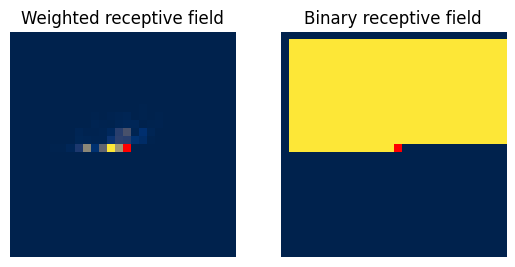

In [16]:
test_model = PixelCNN(c_in=1, c_hidden=64)
inp = torch.zeros(1,1,28,28)
inp.requires_grad_()
out = test_model(inp)
show_center_recep_field(inp, out.squeeze(dim=2))
del inp, out, test_model

Загружаем **обученную модель** (обучение долгое, поэтому его пропускаем):

In [17]:
def train_model(**kwargs):
    # Create a PyTorch Lightning trainer with the generation callback
    trainer = pl.Trainer(default_root_dir=os.path.join(CHECKPOINT_PATH, "PixelCNN"),
                         accelerator="gpu" if str(device).startswith("cuda") else "cpu",
                         devices=1,
                         max_epochs=150,
                         callbacks=[ModelCheckpoint(save_weights_only=True, mode="min", monitor="val_bpd"),
                                    LearningRateMonitor("epoch")])
    result = None
    # Check whether pretrained model exists. If yes, load it and skip training
    pretrained_filename = os.path.join(CHECKPOINT_PATH, "PixelCNN.ckpt")
#    pretrained_filename = ""
    if os.path.isfile(pretrained_filename):
        print("Found pretrained model, loading...")
        model = PixelCNN.load_from_checkpoint(pretrained_filename)
        ckpt = torch.load(pretrained_filename, map_location=device)
        result = ckpt.get("result", None)
    else:
        model = PixelCNN(**kwargs)
        trainer.fit(model, train_loader, val_loader)
    model = model.to(device)

    if result is None:
        # Test best model on validation and test set
        val_result = trainer.test(model, val_loader, verbose=False)
        test_result = trainer.test(model, test_loader, verbose=False)
        result = {"test": test_result, "val": val_result}
    return model, result

In [18]:
model, result = train_model(c_in=1, c_hidden=64)
test_res = result["test"][0]
print("Test bits per dimension: %4.3fbpd" % (test_res["test_loss"] if "test_loss" in test_res else test_res["test_bpd"]))

INFO:pytorch_lightning.utilities.rank_zero:GPU available: True (cuda), used: True
INFO:pytorch_lightning.utilities.rank_zero:TPU available: False, using: 0 TPU cores
INFO:pytorch_lightning.utilities.rank_zero:💡 Tip: For seamless cloud logging and experiment tracking, try installing [litlogger](https://pypi.org/project/litlogger/) to enable LitLogger, which logs metrics and artifacts automatically to the Lightning Experiments platform.


Found pretrained model, loading...


INFO:pytorch_lightning.utilities.migration.utils:Lightning automatically upgraded your loaded checkpoint from v0.9.0 to v2.6.6. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint ../saved_models/ar_models/PixelCNN.ckpt`


Test bits per dimension: 0.808bpd


## 4. Метрика BPD: сколько бит нужно на один пиксель

### Как вообще оценить генеративную модель?

У классификатора есть accuracy. У генеративной модели «правильного ответа» нет. Зато авторегрессионная модель умеет делать важную вещь: **точно посчитать вероятность любой картинки**:

$$p(\mathbf{x}) = \prod_{i} p(x_i \mid x_{<i})$$

Идея оценки: **хорошая модель должна давать высокую вероятность настоящим картинкам из теста**, которые она не видела.

Но у самого числа $p(\mathbf{x})$ две проблемы:
1. Это произведение 784 чисел меньше единицы, то есть очень маленькое число (для нашей модели примерно $2^{-630} \approx 10^{-190}$). → Берём **логарифм**: произведение превращается в сумму.
2. Сумма растёт с размером картинки, и модели на картинках разного размера не сравнить. → **Делим на число пикселей** (точнее, на число «измерений» $H \cdot W \cdot C$, отсюда *per dimension*).

И берём логарифм **по основанию 2**, чтобы получить ответ в битах:

$$
\text{BPD} = \frac{1}{H \cdot W \cdot C} \sum_{c,h,w} -\log_2 p\left(x_{c,h,w} \mid \text{предыдущие пиксели}\right)
$$

где $p(x_{c,h,w} \mid \dots)$ — вероятность, которую модель дала **правильному** значению пикселя.

### Почему именно «биты»?

Из теории информации (Шеннон): если событие происходит с вероятностью $p$, то оптимальный код для него занимает $-\log_2 p$ бит.
* Модель уверена в правильном ответе → он «дешёвый».
* Правильный ответ для модели неожиданный → он «дорогой».

Получается, $-\log_2 p$ — это **«цена удивления»** модели на одном пикселе, а BPD — средняя цена удивления.

In [21]:
for p in [1.0, 0.9, 0.5, 0.1, 1/256, 0.001]:
    print(f"модель дала правильному значению p = {p:<8.4g} →  {-np.log2(p) + 0.0:5.2f} бит")

модель дала правильному значению p = 1        →   0.00 бит
модель дала правильному значению p = 0.9      →   0.15 бит
модель дала правильному значению p = 0.5      →   1.00 бит
модель дала правильному значению p = 0.1      →   3.32 бит
модель дала правильному значению p = 0.003906 →   8.00 бит
модель дала правильному значению p = 0.001    →   9.97 бит


**Ориентиры:**
* **8 bpd** — модель, которая ничего не знает и даёт каждому из 256 значений вероятность $1/256$. Это ровно один байт на пиксель, как при хранении картинки «как есть».
* **0 bpd** — идеальная модель, которая всегда уверена и всегда права. Недостижимо: в данных есть настоящая случайность (почерк у всех разный).
* **Чем меньше, тем лучше.**

**Предсказывать = сжимать.** Это не просто аналогия: модель с BPD = 0.8 вместе с арифметическим кодированием реально сжимает картинку примерно до $0.8 \cdot 784 \approx 630$ бит вместо $8 \cdot 784 = 6272$, то есть примерно **в 10 раз**.

### BPD — это наш лосс

Посмотрите на `calc_likelihood` в классе модели:

```python
nll = F.cross_entropy(pred, x, reduction='none')     # -ln p для каждого пикселя (в натах)
bpd = nll.mean(dim=[1,2,3]) * np.log2(np.exp(1))     # усредняем по пикселям и переводим наты в биты
```

`cross_entropy` считает $-\ln p$ (натуральный логарифм, единицы — **наты**). Умножение на $\log_2 e = 1/\ln 2 \approx 1.44$ переводит наты в биты.

То есть **BPD — это обычный cross-entropy loss, усреднённый по пикселям и записанный в битах**. Модель на обучении напрямую минимизировала BPD, и одно и то же число служит и функцией потерь, и метрикой качества.

### Где модель тратит биты?

Посчитаем «цену» $-\log_2 p$ **для каждого пикселя** нескольких тестовых картинок и нарисуем её как тепловую карту.

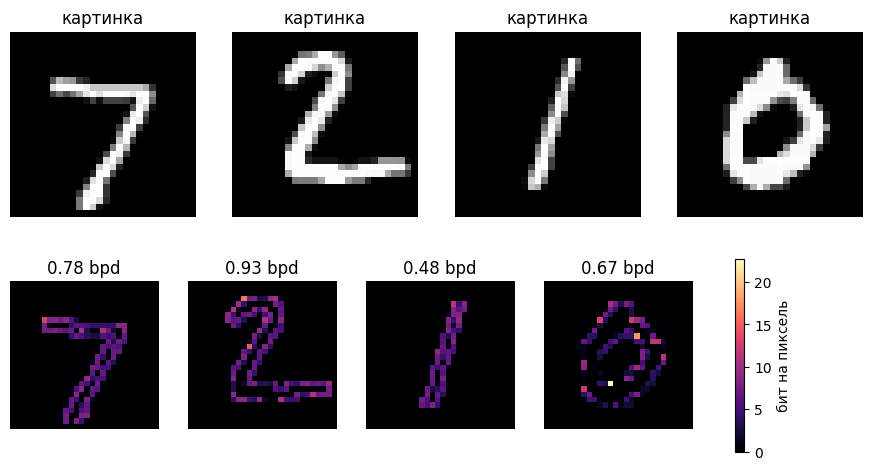

Картинка 0: 610 бит с моделью против 6272 бит в сыром виде (в 10.3 раз меньше)


In [22]:
model.eval()
imgs = torch.stack([test_set[i][0] for i in range(4)]).to(device)   # [4, 1, 28, 28], значения 0..255

with torch.no_grad():
    logits = model(imgs)                                   # [4, 256, 1, 28, 28] — 256 логитов на пиксель
    nll = F.cross_entropy(logits, imgs, reduction='none')  # [4, 1, 28, 28] — -ln p для каждого пикселя
bits = (nll / np.log(2)).cpu()                             # переводим в биты

fig, ax = plt.subplots(2, 4, figsize=(11, 5.5))
for i in range(4):
    ax[0, i].imshow(imgs[i, 0].cpu(), cmap='gray')
    ax[0, i].set_title("картинка")
    im = ax[1, i].imshow(bits[i, 0], cmap='magma', vmin=0, vmax=bits.max().item())
    ax[1, i].set_title(f"{bits[i].mean().item():.2f} bpd")
for a in ax.flat:
    a.axis('off')
fig.colorbar(im, ax=ax[1, :].tolist(), label="бит на пиксель")
plt.show()

total = bits[0].sum().item()
print(f"Картинка 0: {total:.0f} бит с моделью против {28*28*8} бит в сыром виде (в {28*28*8/total:.1f} раз меньше)")

**Что видно:**
* **Фон почти бесплатный**: модель уверена, что вокруг чёрного будет чёрное.
* **Биты уходят на штрихи**, особенно на края и на место, где штрих только начинается. Там модель действительно не может знать заранее, как именно человек провёл линию.

Итоговый BPD — это среднее по всем пикселям всех тестовых картинок.

### Лестница моделей: от «ничего не знаю» до PixelCNN

Чтобы почувствовать, что значит 0.8 bpd, сравним с простыми моделями. Все они оцениваются **одной и той же формулой**, разница только в том, откуда берутся вероятности $p$:

1. **Равномерная модель**: $p = 1/256$ для любого пикселя.
2. **Общая гистограмма**: считаем по трейну, как часто встречается каждое значение 0…255. Все пиксели считаются независимыми и одинаковыми. Модель знает, что фон чаще всего чёрный.
3. **Гистограмма для каждой позиции**: своя гистограмма для каждого из 784 мест. Модель знает, *где* обычно бывает цифра, но не смотрит на соседей.
4. **PixelCNN**: учитывает контекст, то есть все предыдущие пиксели.

Для сравнения добавим **zlib**: обычный архиватор, который ничего не знает про цифры. Для него BPD — это просто размер сжатого файла в битах, делённый на число пикселей.

In [23]:
import zlib

# Все картинки в виде тензоров [N, 784] со значениями 0..255
train_flat = torch.cat([x for x, _ in data.DataLoader(train_set, batch_size=1000)]).view(-1, 784)
test_flat  = torch.cat([x for x, _ in data.DataLoader(test_set,  batch_size=1000)]).view(-1, 784)

def bpd(p_true):
    # p_true — вероятности, которые модель дала правильным значениям пикселей
    return (-torch.log2(p_true)).mean().item()

# 2) Общая гистограмма (+1 к счётчикам, чтобы ни одно значение не получило вероятность 0)
counts = torch.bincount(train_flat.flatten(), minlength=256).float() + 1
hist = counts / counts.sum()
bpd_hist = bpd(hist[test_flat])

# 3) Своя гистограмма для каждой из 784 позиций
counts_pos = torch.ones(784, 256)
counts_pos.scatter_add_(1, train_flat.T.contiguous(), torch.ones(784, len(train_flat)))
hist_pos = counts_pos / counts_pos.sum(dim=1, keepdim=True)
bpd_pos = bpd(hist_pos.gather(1, test_flat.T.contiguous()))

# Для сравнения — zlib: сжимаем каждую тестовую картинку отдельно
raw = test_flat.to(torch.uint8).numpy()
bpd_zlib = np.mean([len(zlib.compress(r.tobytes(), 9)) * 8 / r.size for r in raw])

# 4) PixelCNN (посчитано выше на тестовой выборке)
bpd_pixelcnn = test_res["test_loss"] if "test_loss" in test_res else test_res["test_bpd"]

rows = [("1) Равномерно, p = 1/256", 8.0),
        ("2) Общая гистограмма значений", bpd_hist),
        ("3) Гистограмма для каждой позиции", bpd_pos),
        ("4) PixelCNN", bpd_pixelcnn),
        ("   для сравнения: архиватор zlib", bpd_zlib)]
for name, v in rows:
    print(f"{name:<36} {v:5.2f} bpd   (сжатие в {8 / v:4.1f} раз)")

1) Равномерно, p = 1/256              8.00 bpd   (сжатие в  1.0 раз)
2) Общая гистограмма значений         1.97 bpd   (сжатие в  4.1 раз)
3) Гистограмма для каждой позиции     1.69 bpd   (сжатие в  4.7 раз)
4) PixelCNN                           0.81 bpd   (сжатие в  9.9 раз)
   для сравнения: архиватор zlib      1.94 bpd   (сжатие в  4.1 раз)


Модели 1 → 4 знают о данных всё больше и поэтому всё меньше «удивляются» тестовым картинкам. PixelCNN выигрывает за счёт **контекста**: глядя на уже нарисованную часть цифры, она гораздо увереннее предсказывает следующий пиксель.

**Важно:** BPD можно сравнивать только **на одном и том же датасете**. MNIST сильно проще цветных фотографий. Для ориентира, результаты на CIFAR-10 (цветные 32×32) из статей:

| Модель | BPD на CIFAR-10 |
|---|---|
| RealNVP (normalizing flow) | 3.49 |
| Glow (normalizing flow) | 3.35 |
| PixelCNN (первая версия) | 3.14 |
| Gated PixelCNN (как у нас) | 3.03 |
| PixelCNN++ | 2.92 |

Авторегрессионные модели здесь лучше потоков, но генерируют намного медленнее.

### Вопросы для обсуждения

1. Какой BPD у модели, которая **всегда** даёт правильному значению вероятность 1/2?
2. Что будет с BPD, если модель хоть раз даст правильному значению вероятность **0**?
3. Можно ли сказать, что модель с 0.8 bpd на MNIST лучше модели с 3.0 bpd на CIFAR-10?

<details>
<summary>Ответы</summary>

1. Ровно **1 bpd**: $-\log_2 \frac{1}{2} = 1$.
2. **Бесконечность**: $-\log_2 0 = \infty$. Поэтому модели выдают вероятности через softmax (там нулей не бывает), а в гистограммах выше мы прибавляли 1 к счётчикам.
3. **Нет**: датасеты разной сложности, BPD сравнивают только на одних и тех же данных.

</details>

## 5. Генерация

Генерация идёт ровно так, как в формуле: начинаем с пустой картинки, предсказываем распределение для первого пикселя, **сэмплируем** значение, подставляем его, переходим к следующему пикселю и т.д. Для 28×28 это **784 прохода сети**, поэтому генерация медленная (даже на GPU ячейка работает заметное время).

INFO:lightning_fabric.utilities.seed:Seed set to 1


  0%|          | 0/28 [00:00<?, ?it/s]

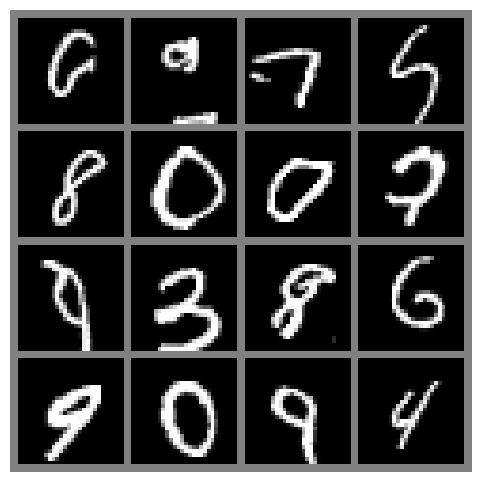

In [19]:
pl.seed_everything(1)
samples = model.sample(img_shape=(16,1,28,28))
show_imgs(samples.cpu())

Большинство картинок узнаются как цифры, хотя некоторые получаются неразборчивыми: маленькой модели не хватает контекста.

### Автодополнение

Раз модель генерирует пиксели по порядку, можно **задать верхнюю часть картинки** и попросить дорисовать низ. Берём три картинки из трейна, стираем нижнюю половину и генерируем 12 вариантов продолжения для каждой.

Original image and input image to sampling:


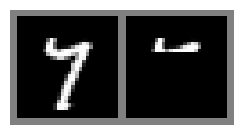

INFO:lightning_fabric.utilities.seed:Seed set to 1


  0%|          | 0/28 [00:00<?, ?it/s]

Autocompletion samples:


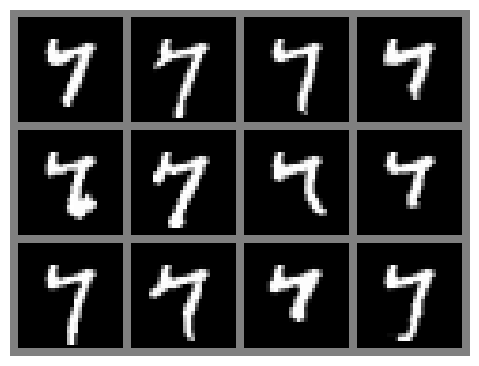

Original image and input image to sampling:


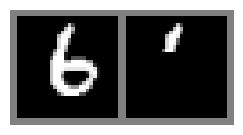

INFO:lightning_fabric.utilities.seed:Seed set to 1


  0%|          | 0/28 [00:00<?, ?it/s]

Autocompletion samples:


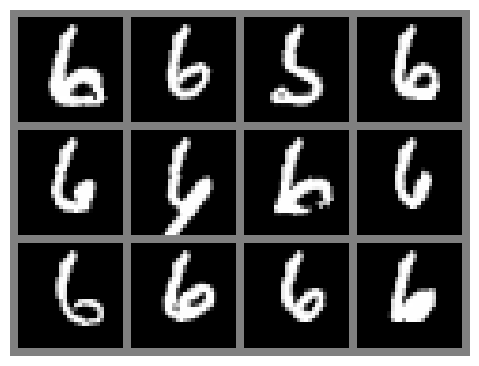

Original image and input image to sampling:


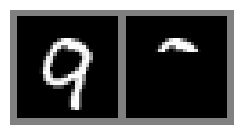

INFO:lightning_fabric.utilities.seed:Seed set to 1


  0%|          | 0/28 [00:00<?, ?it/s]

Autocompletion samples:


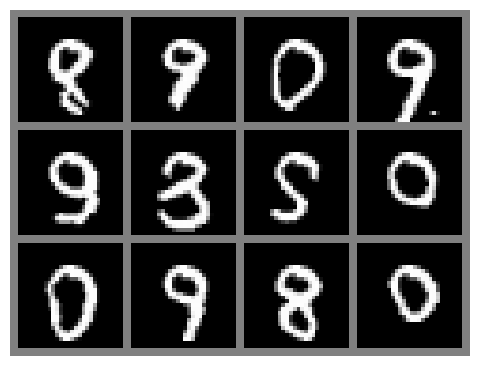

In [20]:
def autocomplete_image(img):
    # Remove lower half of the image
    img_init = img.clone()
    img_init[:,10:,:] = -1
    print("Original image and input image to sampling:")
    show_imgs([img,img_init])
    # Generate 12 example completions
    img_init = img_init.unsqueeze(dim=0).expand(12,-1,-1,-1).to(device)
    pl.seed_everything(1)
    img_generated = model.sample(img_init.shape, img_init)
    print("Autocompletion samples:")
    show_imgs(img_generated)

for i in range(1,4):
    img = train_set[i][0]
    autocomplete_image(img)

Для 7 и 6 все варианты похожи на исходную цифру, но отличаются стилем. А по верхушке девятки модель дорисовывает разные цифры (0, 3, 8, 9): верх неоднозначен, и модель честно отражает эту неопределённость.

## Итоги

* **Авторегрессия для картинок**: предсказываем каждый пиксель по предыдущим, как GPT предсказывает следующий токен. Пиксель — классификация на 256 классов.
* **Маскированные свёртки** не дают модели подглядывать в будущее.
* Наивный стек маскированных свёрток имеет **слепое пятно** справа сверху. Его убирают **два потока**: вертикальный (всё выше) и горизонтальный (текущая строка), информация течёт только из вертикального в горизонтальный.
* **BPD** — средняя «цена» одного пикселя в битах: $-\log_2 p$ правильного значения. Это cross-entropy в битах; 8 bpd — «ничего не знаем», меньше — лучше. Предсказывать = сжимать.
* Главный минус — **медленная генерация**: один проход сети на каждый пиксель.

Что улучшали дальше: PixelCNN++ (другое выходное распределение вместо softmax на 256 классов), PixelSNAIL (добавили attention). Сегодня та же идея «предсказывай следующий токен» работает в генерации картинок через токены изображения.

## Литература
[1] van den Oord, A., et al. "Pixel Recurrent Neural Networks." arXiv preprint arXiv:1601.06759 (2016). [Link](https://arxiv.org/abs/1601.06759)

[2] van den Oord, A., et al. "Conditional Image Generation with PixelCNN Decoders." In Advances in Neural Information Processing Systems 29, pp. 4790–4798 (2016). [Link](http://papers.nips.cc/paper/6527-conditional-image-generation-with-pixelcnn-decoders.pdf)

[3] Salimans, Tim, et al. "PixelCNN++: Improving the PixelCNN with Discretized Logistic Mixture Likelihood and Other Modifications." arXiv preprint arXiv:1701.05517 (2017). [Link](https://arxiv.org/abs/1701.05517)